In [1]:
import os
import torch
import numpy as np
from datasets import load_dataset
from torchvision import transforms
from torch.utils.data import DataLoader
from tqdm import tqdm

In [2]:
# Setup Hardware & Parameters
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
batch_size = 128

# 1. Load Dataset
print("Loading gz10 dataset...")
dataset = load_dataset("MultimodalUniverse/gz10", split="train")

labels = np.array(dataset['gz10_label'])

# 2. Preprocessing Pipe
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def collate_fn(batch):
    images = torch.stack([transform(item['rgb_image'].convert('RGB')) for item in batch])
    batch_labels = torch.tensor([item['gz10_label'] for item in batch])
    return images, batch_labels

dataloader = DataLoader(dataset, batch_size=batch_size, num_workers=2, collate_fn=collate_fn)

# 3. Load DINOv2 via Torch Hub (needed for get_intermediate_layers)
model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14').to(device)
model.eval()

# Feature Storage Lists
features_L9_cls, features_L10_cls, features_L11_cls, features_L12_cls = [], [], [], []
features_L12_patch_mean = []
all_labels = []

# 4. Extraction Loop (FP16 for speed)
print("Extracting features (this will take a few minutes)...")
with torch.no_grad(), torch.cuda.amp.autocast():
    for imgs, lbls in tqdm(dataloader):
        imgs = imgs.to(device)

        # Extract last 4 layers
        ret = model.get_intermediate_layers(imgs, n=4, return_class_token=True)

        features_L9_cls.append(ret[0][1].cpu().numpy())
        features_L10_cls.append(ret[1][1].cpu().numpy())
        features_L11_cls.append(ret[2][1].cpu().numpy())
        features_L12_cls.append(ret[3][1].cpu().numpy())

        # Mean pool patch tokens from Layer 12
        features_L12_patch_mean.append(ret[3][0].mean(dim=1).cpu().numpy())
        all_labels.append(lbls.numpy())

# 5. Concatenate and Cache as .npy
os.makedirs("results", exist_ok=True)
np.save("results/L9_cls.npy", np.concatenate(features_L9_cls))
np.save("results/L10_cls.npy", np.concatenate(features_L10_cls))
np.save("results/L11_cls.npy", np.concatenate(features_L11_cls))
np.save("results/L12_cls.npy", np.concatenate(features_L12_cls))
np.save("results/L12_patch_mean.npy", np.concatenate(features_L12_patch_mean))
np.save("results/labels.npy", np.concatenate(all_labels))
print("Feature extraction complete and saved to disk.")

Loading gz10 dataset...


README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

gz10_rgb_images/train-00000-of-00002.par(…): reconstructing file:   0%|          |  0.00B / 1.29GB            

gz10_rgb_images/train-00000-of-00002.par(…): downloading bytes:           |  0.00B            

gz10_rgb_images/train-00001-of-00002.par(…): reconstructing file:   0%|          |  0.00B / 1.24GB            

...

Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 302MB/s]
/tmp/ipykernel_498/3629095498.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast():


Extracting features (this will take a few minutes)...


100%|██████████| 139/139 [01:24<00:00,  1.65it/s]


Feature extraction complete and saved to disk.


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load cached features
L9_cls = np.load("results/L9_cls.npy")
L10_cls = np.load("results/L10_cls.npy")
L11_cls = np.load("results/L11_cls.npy")
L12_cls = np.load("results/L12_cls.npy")
L12_mean_patch = np.load("results/L12_patch_mean.npy")
y = np.load("results/labels.npy")

# Build Feature Sets
feature_sets = {
    "CLS_L9": L9_cls,
    "CLS_L10": L10_cls,
    "CLS_L11": L11_cls,
    "CLS_L12": L12_cls,
    "Mean_Patch_L12": L12_mean_patch,
    "Concat_CLS_L9_L12": np.hstack([L9_cls, L10_cls, L11_cls, L12_cls]) # 1536 dim
}

print(f"Class Distribution: {np.bincount(y)}")

# Prepare Train/Test splits using Stratified 80/20
splits = {}
scaler = StandardScaler()

for name, X in feature_sets.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=42
    )
    # Standardize features
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    splits[name] = {
        "X_train": X_train_scaled, "X_test": X_test_scaled,
        "y_train": y_train, "y_test": y_test
    }
print("Features standardized and stratified splits created.")

Class Distribution: [1081 1853 2645 2027  334 2043 1829 2628 1423 1873]
Features standardized and stratified splits created.


Training probes for CLS_L9...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Training probes for CLS_L10...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Training probes for CLS_L11...


...

Training probes for Mean_Patch_L12...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Training probes for Concat_CLS_L9_L12...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


,Feature Set,Linear Acc,MLP Acc
5,Concat_CLS_L9_L12,0.689402,0.679538
3,CLS_L12,0.685738,0.662627
2,CLS_L11,0.692503,0.660654
1,CLS_L10,0.678692,0.641488
4,Mean_Patch_L12,0.663754,0.636415
0,CLS_L9,0.684047,0.627959


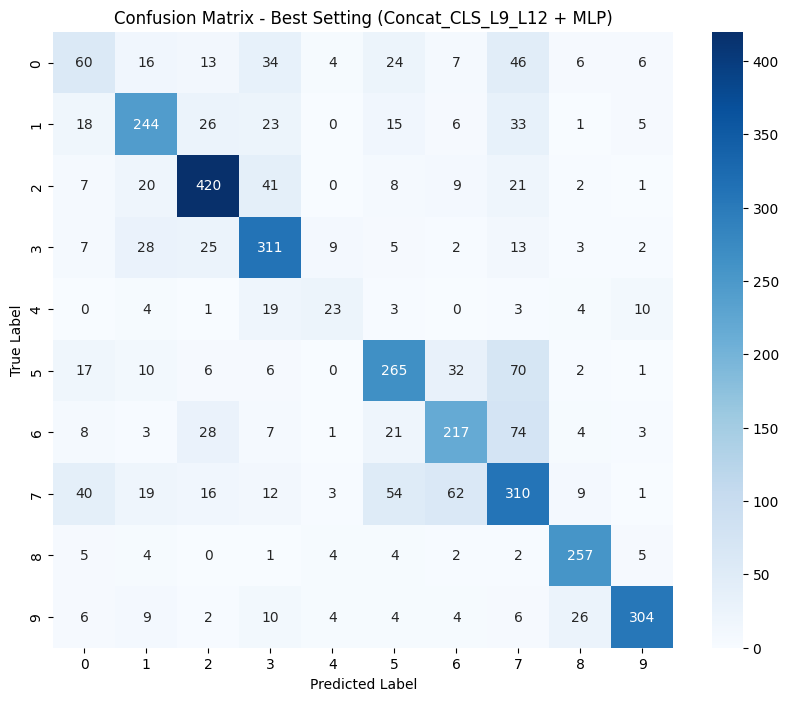

Generating t-SNE plots...


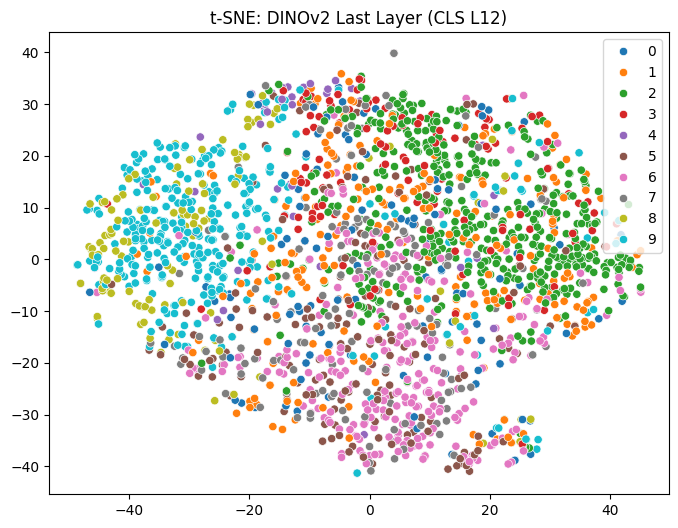

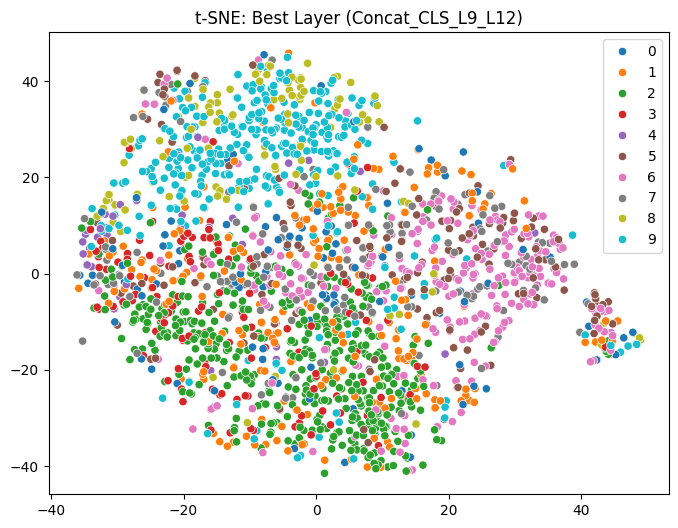

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.manifold import TSNE

results = []
models_cache = {}

# 1. Train Probes
for name, data in splits.items():
    print(f"Training probes for {name}...")
    X_tr, X_te, y_tr, y_te = data["X_train"], data["X_test"], data["y_train"], data["y_test"]

    # Linear Probe
    lr = LogisticRegression(max_iter=1000, random_state=42)
    lr.fit(X_tr, y_tr)
    lr_acc = accuracy_score(y_te, lr.predict(X_te))

    # MLP Probe (1 hidden layer of 256, ReLU, Adam, 30 epochs, batch 64)
    mlp = MLPClassifier(hidden_layer_sizes=(256,), activation='relu', solver='adam',
                        batch_size=64, max_iter=30, random_state=42)
    mlp.fit(X_tr, y_tr)
    mlp_acc = accuracy_score(y_te, mlp.predict(X_te))

    results.append({"Feature Set": name, "Linear Acc": lr_acc, "MLP Acc": mlp_acc})
    models_cache[name] = {"MLP": mlp, "LR": lr}

# Display Results Table
results_df = pd.DataFrame(results).sort_values(by="MLP Acc", ascending=False)
display(results_df)

# 2. Confusion Matrix for the Best Setting
best_setting = results_df.iloc[0]["Feature Set"]
best_mlp = models_cache[best_setting]["MLP"]
y_pred = best_mlp.predict(splits[best_setting]["X_test"])
cm = confusion_matrix(splits[best_setting]["y_test"], y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix - Best Setting ({best_setting} + MLP)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# 3. t-SNE Visualization (Last Layer vs Best Layer)
def plot_tsne(features, labels, title):
    tsne = TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto')
    reduced = tsne.fit_transform(features[:2000]) # Subsample to save time
    plt.figure(figsize=(8, 6))
    sns.scatterplot(x=reduced[:,0], y=reduced[:,1], hue=labels[:2000], palette="tab10", legend="full")
    plt.title(title)
    plt.show()

print("Generating t-SNE plots...")
plot_tsne(feature_sets["CLS_L12"], y, "t-SNE: DINOv2 Last Layer (CLS L12)")
if best_setting != "CLS_L12":
    plot_tsne(feature_sets[best_setting], y, f"t-SNE: Best Layer ({best_setting})")